# Aplikasi Data Mining Clustering Segmentasi Konsumen (K-Means + Streamlit)

## Tujuan Pembelajaran & Konteks Proyek
Notebook ini mempelajari **Unsupervised Learning - Clustering**, yaitu mengelompokkan pelanggan mal (`Mall_Customers.csv`) ke dalam beberapa segmen berdasarkan usia (`Age`), pendapatan tahunan (`Annual Income`), dan skor pengeluaran belanja (`Spending Score`) **tanpa memiliki label kelas sebelumnya**.

### Mengapa Menggunakan Algoritma *K-Means Clustering*?
1. **Data Tidak Berlabel (*Unsupervised*):** Di dunia nyata, perusahaan ritel memiliki data transaksi dan profil pelanggan, tetapi belum tahu ada berapa tipe segmen pelanggan di dalamnya.
2. **Cara Kerja yang Intuitif (Berbasis *Centroid*):**
   - K-Means menentukan $K$ titik pusat klaster (*centroid*).
   - Setiap pelanggan dimasukkan ke klaster dengan jarak Euclidean terdekat ke *centroid*-nya.
   - Posisi *centroid* diperbarui secara iteratif berdasarkan rata-rata anggota klaster hingga posisi klaster stabil (konvergen).
3. **Mengapa Menggunakan *Elbow Method* (Metode Siku)?**
   - Karena K-Means mewajibkan kita menentukan jumlah klaster ($K$) di awal, kita menguji nilai $K = 1$ sampai $10$ dan menghitung **Inertia (Within-Cluster Sum of Squares / WCSS)**, yaitu total kuadrat jarak tiap titik ke *centroid* klasternya.
   - Titik lekukan tajam seperti siku (*elbow*, pada dataset ini berada di sekitar $K = 3$ hingga $K = 5$) menunjukkan jumlah klaster paling optimal: menambah klaster lebih dari titik tersebut tidak lagi menurunkan *inertia* secara signifikan.

### Trade-offs (Kelebihan vs Keterbatasan)
- **Kelebihan:** Sangat cepat, mudah divisualisasikan pada ruang 2D (`Income` vs `Score`), dan hasilnya langsung dapat ditindaklanjuti oleh tim pemasaran (misalnya: segmen *Pendapatan Tinggi - Belanja Rendah* diberi promo khusus).
- **Keterbatasan:** Harus menentukan nilai $K$ di awal, sensitif terhadap *outlier*, dan mengasumsikan bentuk klaster cenderung bulat (*spherical*).

**Catatan Penggunaan:**
* **Di VS Code Lokal:** Pastikan `Mall_Customers.csv` berada satu folder dengan notebook ini.
* **Di Google Colab:** Unggah `Mall_Customers.csv` ke panel **Files** di sebelah kiri sebelum menjalankan.

In [5]:
# 1. Install library yang dibutuhkan ke kernel aktif
%pip install -q streamlit scikit-learn pandas matplotlib seaborn openpyxl
print('Instalasi library selesai!')


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Instalasi library selesai!


## Bagian 1: Preparation Model & Clustering di Notebook (Video 1)

5 Data Pertama:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset setelah persiapan (X):


/var/folders/40/wzkljfls7l3ffsrnlth7bx1w0000gn/T/ipykernel_85579/4077061967.py:12: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(index=str, columns={


,Age,Income,Score
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


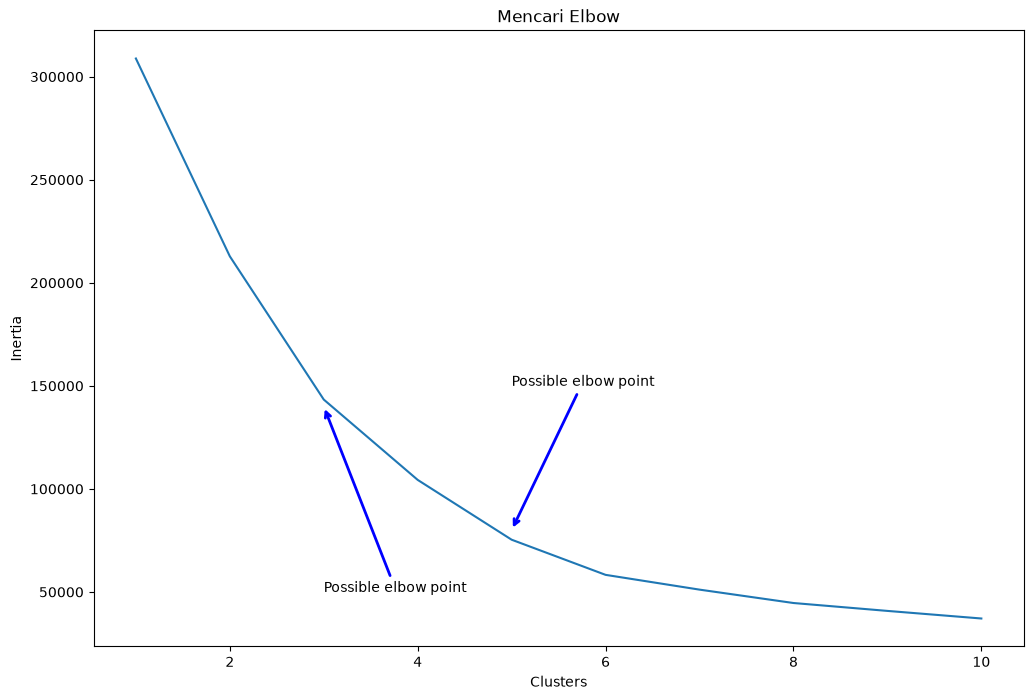

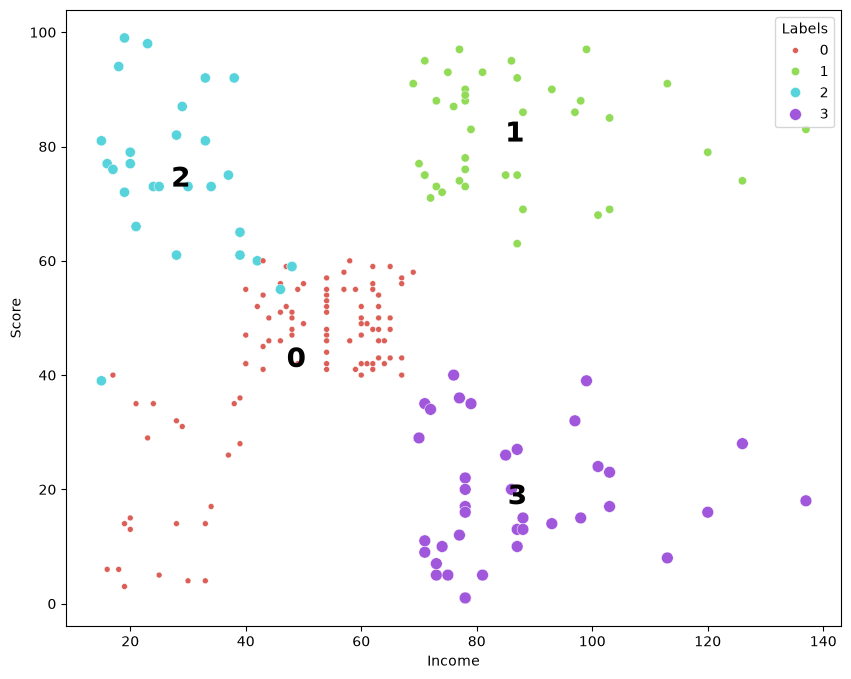

Hasil klaster berhasil disimpan ke output_cluster.xlsx


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Membaca Dataset
df = pd.read_csv('Mall_Customers.csv')
print('5 Data Pertama:')
display(df.head())

# Persiapan Dataset (Rename & Drop Kolom)
df.rename(index=str, columns={
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'Score'
}, inplace=True)

X = df.drop(['CustomerID', 'Gender'], axis=1)
print('\nDataset setelah persiapan (X):')
display(X.head())

# Menentukan Jumlah Cluster dengan Elbow
clusters = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, n_init=10, random_state=42).fit(X)
    clusters.append(km.inertia_)

fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(x=list(range(1, 11)), y=clusters, ax=ax)
ax.set_title('Mencari Elbow')
ax.set_xlabel('Clusters')
ax.set_ylabel('Inertia')

# Panah Elbow
ax.annotate('Possible elbow point', xy=(3, 140000), xytext=(3, 50000), xycoords='data',
            arrowprops=dict(arrowstyle='->', connectionstyle='arc3', color='blue', lw=2))
ax.annotate('Possible elbow point', xy=(5, 80000), xytext=(5, 150000), xycoords='data',
            arrowprops=dict(arrowstyle='->', connectionstyle='arc3', color='blue', lw=2))
plt.show()

# Proses Clustering dengan K=4
n_clust = 4
kmean = KMeans(n_clusters=n_clust, n_init=10, random_state=42).fit(X)
X['Labels'] = kmean.labels_

plt.figure(figsize=(10, 8))
sns.scatterplot(x=X['Income'], y=X['Score'], hue=X['Labels'], markers=True,
                size=X['Labels'], palette=sns.color_palette('hls', n_clust))

for label in X['Labels'].unique():
    plt.annotate(label,
                 (X[X['Labels'] == label]['Income'].mean(),
                  X[X['Labels'] == label]['Score'].mean()),
                 horizontalalignment='center',
                 verticalalignment='center',
                 size=20, weight='bold',
                 color='black')
plt.show()

# Simpan ke Excel
X.to_excel('output_cluster.xlsx', index=False)
print('Hasil klaster berhasil disimpan ke output_cluster.xlsx')

## Bagian 2: Membuat File Aplikasi Streamlit `mall-customer.py` (Video 2)

In [7]:
%%writefile mall-customer.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv('Mall_Customers.csv')

df.rename(index=str, columns={
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'Score'
}, inplace=True)

X = df.drop(['CustomerID', 'Gender'], axis=1)

st.header("Isi Dataset")
st.write(X)

# Menampilkan Panah Elbow
clusters = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, n_init=10, random_state=42).fit(X)
    clusters.append(km.inertia_)

fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(x=list(range(1, 11)), y=clusters, ax=ax)
ax.set_title('Mencari Elbow')
ax.set_xlabel('Clusters')
ax.set_ylabel('Inertia')

ax.annotate('Possible elbow point', xy=(3, 140000), xytext=(3, 50000), xycoords='data',
            arrowprops=dict(arrowstyle='->', connectionstyle='arc3', color='blue', lw=2))
ax.annotate('Possible elbow point', xy=(5, 80000), xytext=(5, 150000), xycoords='data',
            arrowprops=dict(arrowstyle='->', connectionstyle='arc3', color='blue', lw=2))

st.header("Elbow Point")
st.pyplot(fig)

# Sidebar jumlah K
st.sidebar.subheader("Nilai Jumlah K")
clust = st.sidebar.slider("Pilih jumlah cluster :", 2, 10, 3, 1)

def k_means(n_clust):
    kmean = KMeans(n_clusters=n_clust, n_init=10, random_state=42).fit(X)
    X['Labels'] = kmean.labels_

    fig_cluster = plt.figure(figsize=(10, 8))
    sns.scatterplot(x=X['Income'], y=X['Score'], hue=X['Labels'], markers=True,
                    size=X['Labels'], palette=sns.color_palette('hls', n_clust))

    for label in X['Labels'].unique():
        plt.annotate(label,
                     (X[X['Labels'] == label]['Income'].mean(),
                      X[X['Labels'] == label]['Score'].mean()),
                     horizontalalignment='center',
                     verticalalignment='center',
                     size=20, weight='bold',
                     color='black')

    st.header('Cluster Plot')
    st.pyplot(fig_cluster)
    st.write(X)

k_means(clust)

Overwriting mall-customer.py


## Bagian 3: Menjalankan Aplikasi Streamlit (VS Code Lokal & Google Colab)
Sel di bawah ini otomatis menyesuaikan environment: membuka di `http://localhost:8501` jika dijalankan di VS Code lokal, atau membuat tautan `.trycloudflare.com` jika dijalankan di Google Colab.

In [8]:
import sys
import subprocess
import time

IN_COLAB = 'google.colab' in sys.modules

streamlit_proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "mall-customer.py", "--server.port", "8502", "--server.headless", "true"],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(3)

if IN_COLAB:
    subprocess.run(["wget", "-q", "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64", "-O", "cloudflared"], check=True)
    subprocess.run(["chmod", "+x", "cloudflared"], check=True)
    print('Membuka Cloudflare Tunnel... Klik link .trycloudflare.com yang muncul di bawah ini:')
    !./cloudflared tunnel --url http://localhost:8502 --no-autoupdate
else:
    print('Server Streamlit (Customer Clustering) telah berjalan di background!')
    print('Buka di browser: http://localhost:8502')

Server Streamlit (Customer Clustering) telah berjalan di background!
Buka di browser: http://localhost:8502
